In [61]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

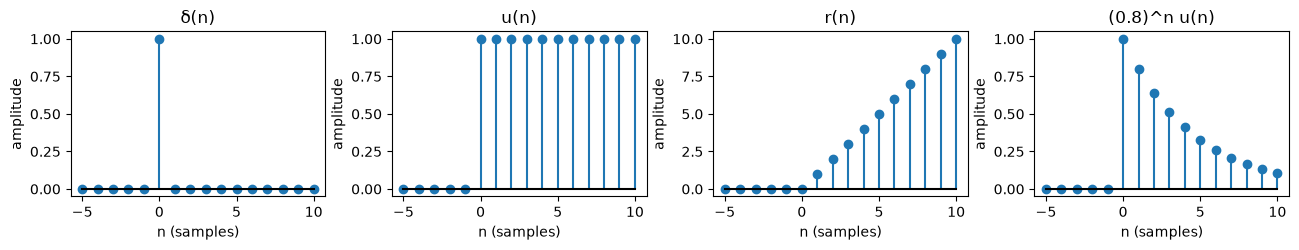

In [62]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step  = (n >= 0).astype(float)
ramp  = n * step
expo  = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

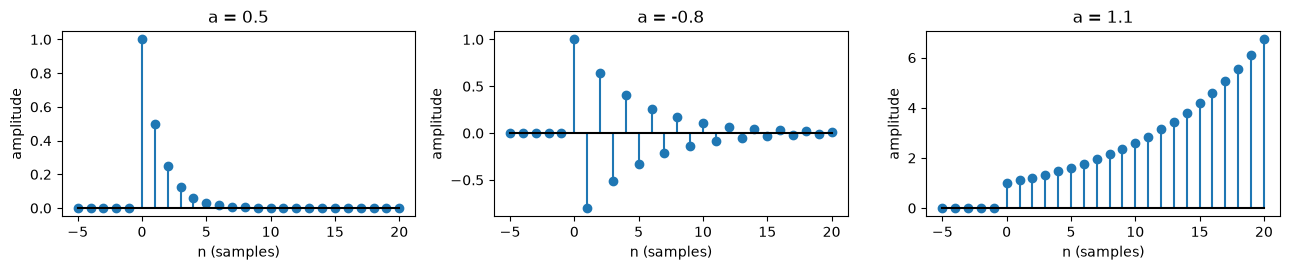

In [63]:
n = np.arange(-5, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, (a**n.astype(float)) * (n >= 0), basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

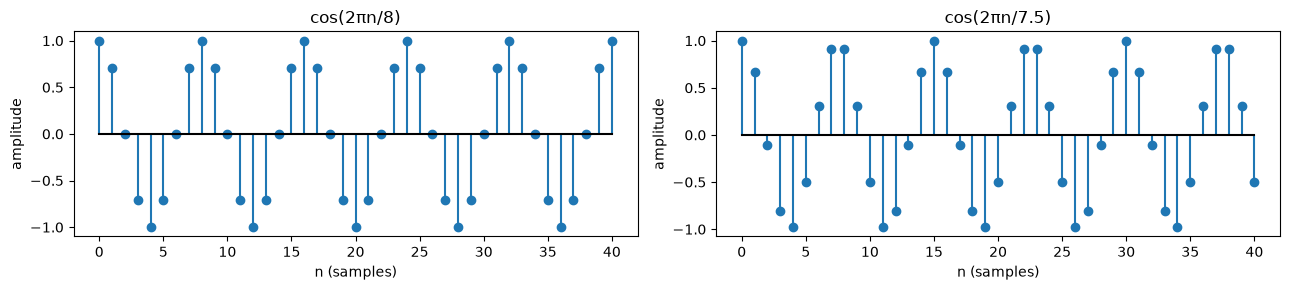

In [64]:
n = np.arange(0, 41)
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
for ax, N0, lab in zip(axes, [8, 7.5], ["cos(2πn/8)", "cos(2πn/7.5)"]):
    ax.stem(n, np.cos(2*np.pi*n/N0), basefmt="k-")
    ax.set_title(lab); ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

cos(2πn/8) repeats every 8 samples. cos(2πn/7.5) has f = 2/15, so it repeats only every 15 samples.

fs = 44100 Hz, duration = 6.76 s, samples = 297980


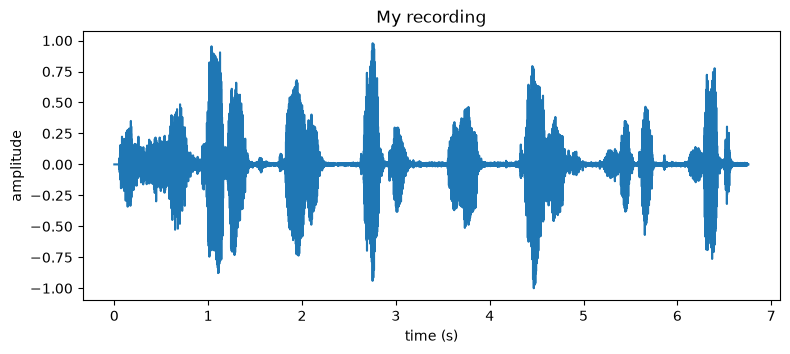

In [65]:
import os
fname = "mk.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [66]:
with open("mk.wav", "rb") as f:
    print(f.read(12))
import os
print(os.getcwd())

b'RIFF\x140\x12\x00WAVE'
c:\Users\AB GROUP\OneDrive\Documents\COU07506-Labs


In [67]:
print(f"Sampling rate = {fs} Hz")
print(f"Duration      = {len(x)/fs:.2f} s")
print(f"Samples       = {len(x)}")

Sampling rate = 44100 Hz
Duration      = 6.76 s
Samples       = 297980


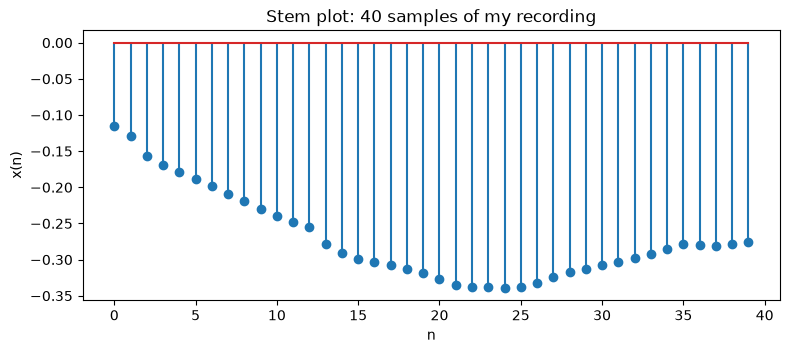

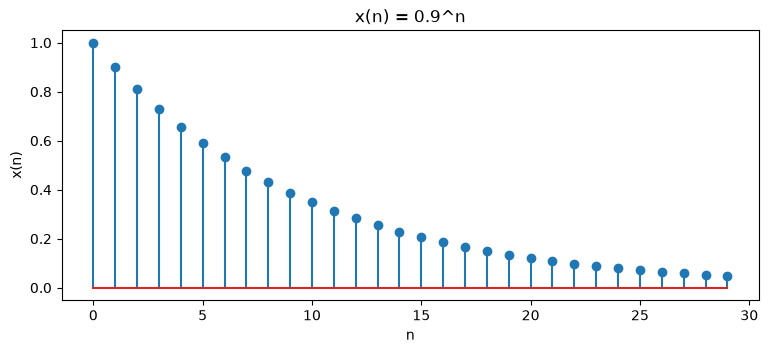

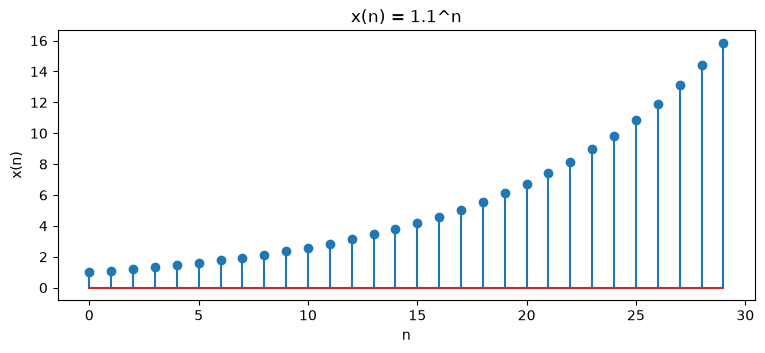

In [68]:
# Stem plot of a short segment of your voice
start = int(3 * fs)          # 3 seconds in, where there is speech
n = np.arange(40)
plt.figure()
plt.stem(n, x[start:start+40])
plt.xlabel("n"); plt.ylabel("x(n)"); plt.title("Stem plot: 40 samples of my recording")
plt.show()

# Exponential signals x(n) = a^n
n = np.arange(0, 30)
for a in [0.9, 1.1]:
    plt.figure()
    plt.stem(n, a**n)
    plt.xlabel("n"); plt.ylabel("x(n)"); plt.title(f"x(n) = {a}^n")
    plt.show()

Analysis Questions

Q1. The sampling rate of my recording is 44,100 Hz. One minute of mono audio needs 44,100 × 60 = 2,646,000 numbers.

Q2. x(n) is a discrete-time signal, defined only at integer values of n. A stem plot shows each sample as an isolated point, while a continuous line wrongly suggests values exist between samples.

Q3. For a = 1.1, aⁿ grows without bound and is not absolutely summable. If it were an impulse response, the system would violate BIBO stability.

Git repository: https://github.com/yuzo192/COU07506-labs